#LECTURE 13 LINEAR REGRESSION - PRINCIPAL COMPOSITE ANALYSIS- PREDICTIONS

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("Starbucks_Stores_Data.xlsx", sheet_name="Stores")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 300 | Columns: 25


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,5.6,4.9,5.7,6.2,6.1,5.0,14.5,281,35.3,79.2
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,6.8,7.1,7.1,6.3,7.0,6.2,14.7,280,40.4,79.9
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,9.0,8.8,9.4,8.8,8.5,3.5,16.1,362,46.1,84.1
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,6.8,6.8,7.2,7.2,7.2,4.8,15.9,291,39.5,85.9
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,6.7,5.6,6.1,7.1,6.3,5.1,19.1,296,37.5,123.0


#DESCRIPTIVE STATISTICS

In [2]:
df.describe().round(1)

,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,Promo_Offers_Count,App_Orders_Share_Pct,Loyalty_Members_K,App_Rating,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
count,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,...,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0
mean,1192.8,45.3,11.7,128.4,86.2,54.0,6.2,25.0,21.6,4.2,...,7.3,7.0,7.5,7.3,7.4,6.1,15.9,310.5,39.4,88.8
std,343.4,13.5,3.1,46.2,33.8,22.4,2.4,7.2,7.4,0.3,...,0.8,1.0,0.8,0.8,0.9,1.5,4.2,25.2,6.8,20.3
min,500.0,14.0,5.0,30.0,15.0,8.0,1.0,6.0,4.0,3.4,...,4.9,4.2,5.7,5.0,4.3,2.5,5.0,235.0,15.0,45.5
25%,950.0,37.0,9.0,95.0,62.8,39.8,4.0,20.3,16.6,4.1,...,6.8,6.3,7.0,6.8,6.8,5.0,12.9,294.0,35.2,75.6
50%,1210.0,45.0,12.0,127.0,85.0,54.0,6.0,25.8,22.0,4.2,...,7.3,7.0,7.4,7.3,7.3,6.0,15.9,310.0,40.0,86.1
75%,1440.0,54.0,14.0,158.0,109.0,69.0,8.0,30.0,26.5,4.4,...,7.8,7.7,8.0,7.7,8.0,7.2,18.6,327.0,44.0,98.1
max,2000.0,80.0,19.0,260.0,179.0,120.0,13.0,48.0,40.1,4.9,...,9.7,10.0,9.7,9.2,9.7,11.1,26.6,382.0,58.1,170.8


#WHICH BUSINESS VARIABLES WE WANT TO RELATE AND WHAT TYPE IS EACH

In [4]:
# Identify numerical and categorical variables

numbers = df.select_dtypes(include="number").columns.tolist()
categories = df.select_dtypes(exclude="number").columns.tolist()

print("Number variables:", len(numbers))
print("Category variables:", categories)

Number variables: 21
Category variables: ['Store_ID', 'City', 'City_Tier', 'Location_Type']


In [5]:
# The nine key variables we will use in Part C

key_cols = [
    'Social_Media_Spend_K',
    'App_Orders_Share_Pct',
    'Seats',
    'Staff_Count',
    'Avg_Bill_Time_Min',
    'Service_Score',
    'Repeat_Customer_Pct',
    'Monthly_Footfall_K',
    'Monthly_Sales_INR_Lakh'
]

#DO STORES WITH A HIGH SHARE OF APP ORDERS CELL MODE
MATPOLIB

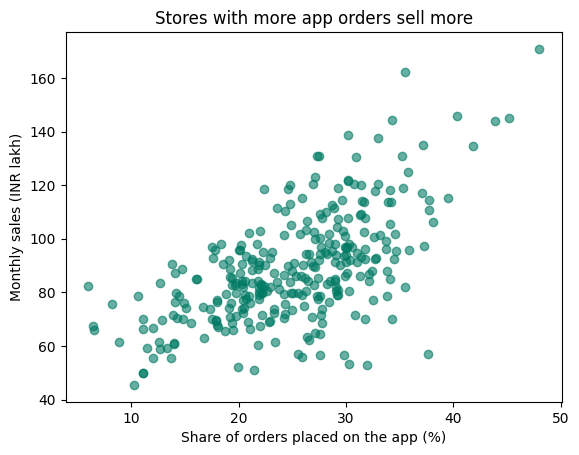

In [6]:
# STEP 4: Positive Relationship (Scatter Plot)

import matplotlib.pyplot as plt

plt.scatter(
    df['App_Orders_Share_Pct'],
    df['Monthly_Sales_INR_Lakh'],
    alpha=0.6,
    color='#007A64'
)

plt.title("Stores with more app orders sell more")
plt.xlabel("Share of orders placed on the app (%)")
plt.ylabel("Monthly sales (INR lakh)")

plt.show()

#NEGATIVE RELATIONSHIP
DO LONGER WAITS MEAN FEWER REPEAT CUSTOMERS

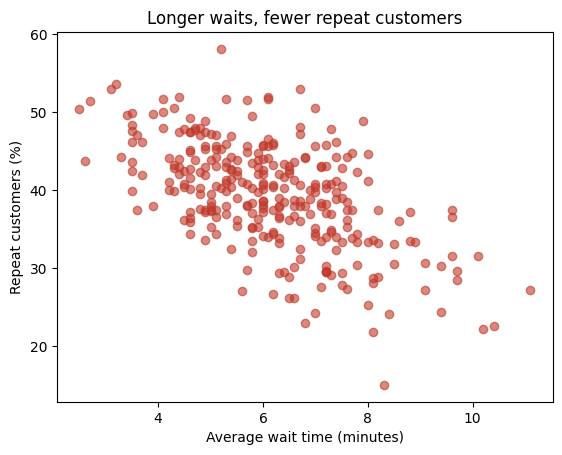

In [7]:
plt.scatter(
    df['Avg_Wait_Time_Min'],
    df['Repeat_Customer_Pct'],
    alpha=0.6,
    color='#C0392B'
)

plt.title("Longer waits, fewer repeat customers")
plt.xlabel("Average wait time (minutes)")
plt.ylabel("Repeat customers (%)")

plt.show()

#NEUTRAL RELATIONSHIP/ NO RELATIONSHIP AMONG VARIBLES
DOES THE BUGGER STORE SERVE BETTER COFFEE

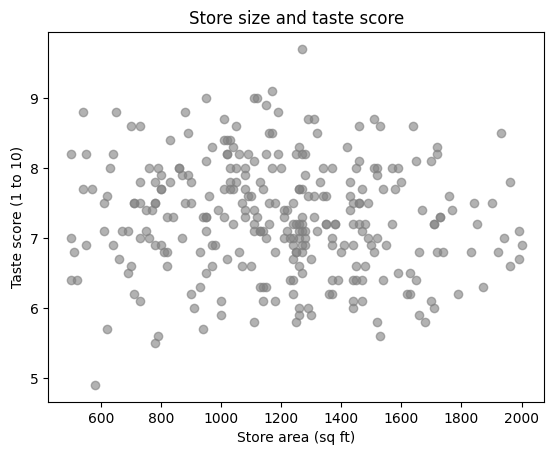

In [8]:
# STEP 6: Store Size and Taste Score

plt.scatter(
    df['Store_Area_SqFt'],
    df['Taste_Score'],
    alpha=0.6,
    color='grey'
)

plt.title("Store size and taste score")
plt.xlabel("Store area (sq ft)")
plt.ylabel("Taste score (1 to 10)")

plt.show()

#CORRELATION COEFFICIENT
HOW STRONG IS THE RELATIONSHIP AMONG VARIABLES AND WHAT IS THE DIRECTION

In [9]:
r1 = df["App_Orders_Share_Pct"].corr(df["Monthly_Sales_INR_Lakh"])
r2 = df["Avg_Wait_Time_Min"].corr(df["Repeat_Customer_Pct"])
r3 = df["Store_Area_SqFt"].corr(df["Taste_Score"])

print("App share and sales correlation:", round(r1, 2))
print("Wait time and repeat correlation:", round(r2, 2))
print("Store area and taste correlation:", round(r3, 2))

App share and sales correlation: 0.61
Wait time and repeat correlation: -0.58
Store area and taste correlation: -0.09


#CORRELATION MATRIX

In [10]:
# Correct the column name in the key columns list to avoid KeyError
key_cols = [
    'Social_Media_Spend_K',
    'App_Orders_Share_Pct',
    'Seats',
    'Staff_Count',
    'Avg_Wait_Time_Min',
    'Service_Score',
    'Repeat_Customer_Pct',
    'Monthly_Footfall_K',
    'Monthly_Sales_INR_Lakh'
]

# Calculate the correlation matrix for the key variables
corr = df[key_cols].corr().round(2)
corr

,Social_Media_Spend_K,App_Orders_Share_Pct,Seats,Staff_Count,Avg_Wait_Time_Min,Service_Score,Repeat_Customer_Pct,Monthly_Footfall_K,Monthly_Sales_INR_Lakh
Social_Media_Spend_K,1.00,0.40,-0.00,0.03,-0.01,-0.06,-0.02,0.32,0.67
App_Orders_Share_Pct,0.40,1.00,-0.03,-0.02,0.03,-0.03,-0.03,0.44,0.61
Seats,-0.00,-0.03,1.00,0.75,0.13,-0.09,-0.07,0.53,0.37
Staff_Count,0.03,-0.02,0.75,1.00,0.07,-0.01,-0.04,0.54,0.30
Avg_Wait_Time_Min,-0.01,0.03,0.13,0.07,1.00,-0.26,-0.58,-0.05,0.04
Service_Score,-0.06,-0.03,-0.09,-0.01,-0.26,1.00,0.75,0.25,-0.01
Repeat_Customer_Pct,-0.02,-0.03,-0.07,-0.04,-0.58,0.75,1.00,0.17,-0.01
Monthly_Footfall_K,0.32,0.44,0.53,0.54,-0.05,0.25,0.17,1.00,0.59
Monthly_Sales_INR_Lakh,0.67,0.61,0.37,0.30,0.04,-0.01,-0.01,0.59,1.00


#HEATMAP
WHERE ARE THE STRONG AND WEAK RELATIONSHIP?

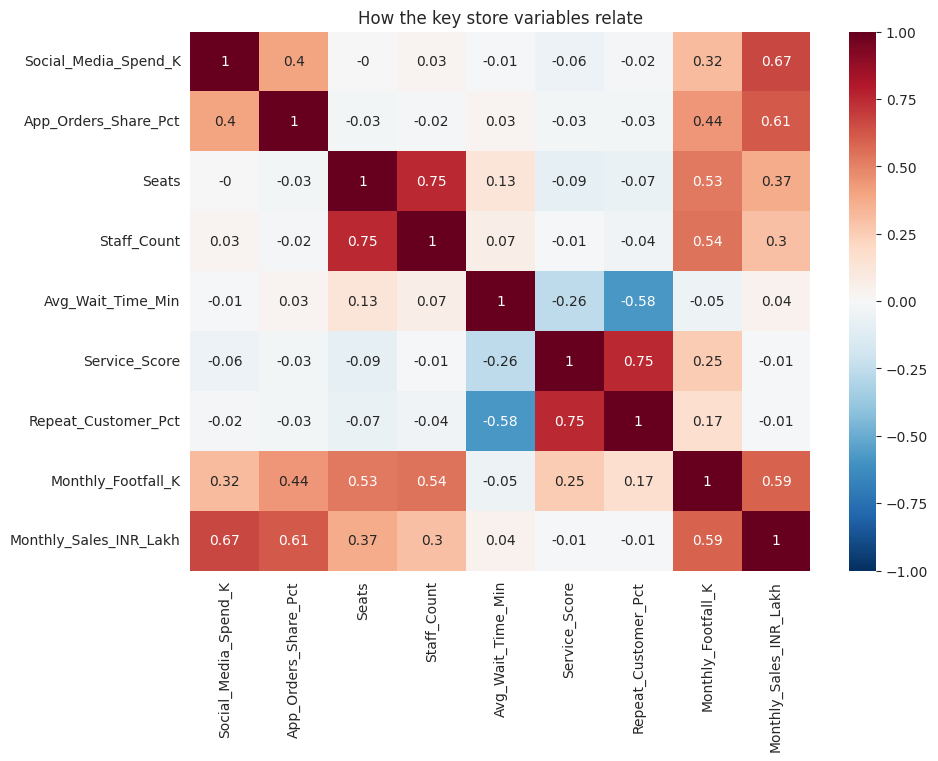

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("How the key store variables relate")
plt.show()

#STATISTICAL MODELLING- LINEAR REGRESSION AND MULTIPLE REGRESSION

In [12]:
import statsmodels.formula.api as smf

# Correcting typos: Monthly_Sales_INR_Lakh, Social_Media_Spend_K, data=df, and adding proper Python 3 print syntax
m_social = smf.ols("Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K", data=df).fit()
print(m_social.summary().tables[1])
print("R-squared:", round(m_social.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               50.9018      2.574     19.775      0.000      45.836      55.967
Social_Media_Spend_K     0.2950      0.019     15.631      0.000       0.258       0.332
R-squared: 0.45


#INTERPRETATION OF LINEAR REGRESSION
IS UNIT DECREASE IN SOCIAL MEDIA SPENDING IS ASSOCIATED WITH 0.295 LAKHS INCREASE IN MONTHLY SALES R SQUARE- SOCIAL MEDIA SEPENDING EXPLAINS 45% OF VARIATION P VALUE/ SIGNIFICANCE VALUE "SOCIAL MEDIA SPENDING AS A STATISCICALLY SIGNIFICANT POSITIVE RELATION WITH MONTHLY SALES

#NEGATIVE RELATION IN LINEAR REGRESSION

In [13]:
m_wait = smf.ols("Repeat_Customer_Pct ~ Avg_Wait_Time_Min", data=df).fit()
print(m_wait.summary().tables[1])
print("R-squared:", round(m_wait.rsquared, 2))

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            55.2749      1.339     41.276      0.000      52.639      57.910
Avg_Wait_Time_Min    -2.5949      0.212    -12.224      0.000      -3.013      -2.177
R-squared: 0.33


#MULTIPLE LINEAR REGRESSION
WHAT ARE THE OTHER ATTRIBUTES THAT CAN AFFECT MONTHLY SALES